In [ ]:
# # IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# # THEN FEEL FREE TO DELETE THIS CELL.
# # NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# # ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# # NOTEBOOK.
# import kagglehub
# mikoajkoek_traffic_road_object_detection_polish_12k_path = kagglehub.dataset_download('mikoajkoek/traffic-road-object-detection-polish-12k')

# print('Data source import complete.')


In [1]:
from transformers import pipeline
import torch
from accelerate.test_utils.testing import get_backend
from PIL import Image
device, _, _ = get_backend()
checkpoint = "Intel/zoedepth-kitti"
pipe = pipeline("depth-estimation", model=checkpoint, device=device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.38G [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Device set to use cuda


In [2]:
!pip install ultralytics

from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 30.6 MB/s eta 0:00:00
Mounted at /content/drive


In [3]:
import os

base_dir = '/content/drive/My Drive/Dataset/traffic-road-object-detection-polish-12k/road_detection/road_detection'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'valid')
test_dir = os.path.join(base_dir, 'test')

assert os.path.exists(base_dir), f"Base directory not found"
assert os.path.exists(train_dir), f"Train directory not found: {train_dir}"
assert os.path.exists(val_dir), f"Validation directory not found: {val_dir}"
assert os.path.exists(test_dir), f"Test directory not found: {test_dir}"

# traffic-road-object-detection-polish-12k/road_detection/road_detection

First Image Shape: (480, 640, 3)
First Image Boxes: [[538, 245, 564, 288], [445, 340, 591, 475], [314, 338, 360, 392], [379, 340, 415, 379], [366, 339, 387, 365], [338, 299, 346, 311], [353, 300, 359, 311], [323, 298, 329, 311]]
First Image Class IDs: [1, 0, 0, 0, 0, 2, 2, 7]


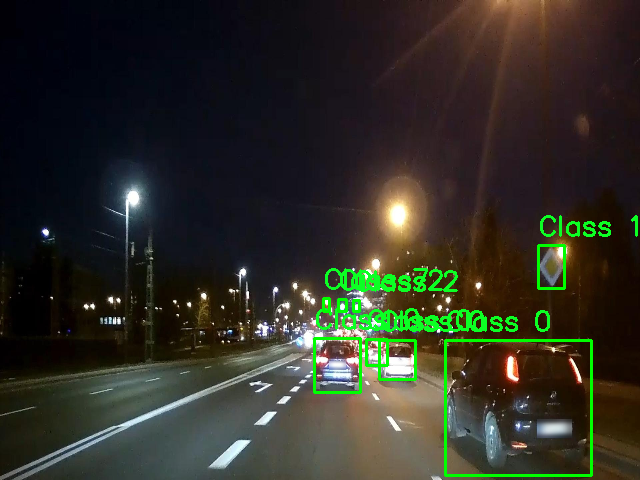

In [4]:
import os
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

# Paths to the dataset directories
train_images_path = os.path.join(test_dir, "images")
train_labels_path = os.path.join(test_dir, "labels")

img_width, img_height = 640, 480  # Assumed image size (adjust based on your actual image size)

# Helper function to parse a single YOLO label line
def parse_yolo_label(label_line):
    label_parts = label_line.strip().split()
    class_id = int(label_parts[0])
    center_x = float(label_parts[1])
    center_y = float(label_parts[2])
    width = float(label_parts[3])
    height = float(label_parts[4])
    return class_id, center_x, center_y, width, height

# Convert YOLO format to bounding box coordinates in image pixel values
def yolo_to_image_coords(center_x, center_y, width, height, img_width, img_height):
    box_x1 = int((center_x - width / 2) * img_width)
    box_y1 = int((center_y - height / 2) * img_height)
    box_x2 = int((center_x + width / 2) * img_width)
    box_y2 = int((center_y + height / 2) * img_height)
    return box_x1, box_y1, box_x2, box_y2

# Load images and corresponding labels
def load_data(images_path, labels_path):
    images = []
    boxes = []
    class_ids = []

    for image_file in os.listdir(images_path):
        if image_file.endswith('.jpg') or image_file.endswith('.png'):
            # Load image
            image_path = os.path.join(images_path, image_file)
            image = cv2.imread(image_path)
            image = cv2.resize(image, (img_width, img_height))  # Adjust size

            # Append image to list
            images.append(image)

            # Load corresponding label
            label_file = os.path.splitext(image_file)[0] + '.txt'
            label_path = os.path.join(labels_path, label_file)

            with open(label_path, 'r') as file:
                label_data = file.readlines()
                image_boxes = []
                image_class_ids = []

                for label_line in label_data:
                    class_id, center_x, center_y, width, height = parse_yolo_label(label_line)
                    box_x1, box_y1, box_x2, box_y2 = yolo_to_image_coords(center_x, center_y, width, height, img_width, img_height)

                    # Append box and class_id to respective lists
                    image_boxes.append([box_x1, box_y1, box_x2, box_y2])
                    image_class_ids.append(class_id)

                boxes.append(image_boxes)
                class_ids.append(image_class_ids)

    return np.array(images), boxes, class_ids

# Load training data
train_images, train_boxes, train_class_ids = load_data(train_images_path, train_labels_path)

# Example: Inspect the first image, boxes, and classes
print("First Image Shape:", train_images[0].shape)
print("First Image Boxes:", train_boxes[0])
print("First Image Class IDs:", train_class_ids[0])

# Visualize an image with bounding boxes drawn
def visualize_image_with_boxes(image, boxes, class_ids):
    for (box, class_id) in zip(boxes, class_ids):
        x1, y1, x2, y2 = box
        # Draw rectangle and class id
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image, f'Class {class_id}', (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (36,255,12), 2)

    # cv2.imshow("Image with Bounding Boxes", image)
    cv2_imshow(image)

# Example visualization
visualize_image_with_boxes(train_images[0].copy(), train_boxes[0], train_class_ids[0])


In [5]:
def visualize_boxes(i):
  visualize_image_with_boxes(train_images[i].copy(), train_boxes[i], train_class_ids[i])

In [6]:
sign_ids = [1,6,8,10]
sign_boxes = []
for i in range(len(train_class_ids)):
  sign_boxes.append([])
  for j in range(len(train_class_ids[i])):
    if train_class_ids[i][j] in sign_ids:
      sign_boxes[i].append(train_boxes[i][j])
print(sign_boxes)
print(len(sign_boxes))

[[[538, 245, 564, 288]], [[193, 321, 221, 363], [548, 260, 614, 301], [424, 249, 456, 300], [375, 328, 381, 335], [374, 318, 382, 328], [383, 296, 406, 322]], [[348, 293, 362, 307]], [[244, 321, 251, 333], [288, 260, 296, 272], [315, 258, 325, 272], [341, 259, 351, 272], [370, 259, 378, 271]], [[349, 328, 356, 338], [215, 317, 222, 326], [84, 322, 99, 341], [214, 306, 222, 316], [348, 319, 356, 330]], [[299, 335, 314, 343]], [[220, 317, 232, 333]], [], [[335, 315, 347, 330], [201, 299, 211, 311], [427, 301, 440, 315]], [[386, 237, 412, 280], [354, 308, 357, 318], [354, 294, 358, 307], [339, 309, 345, 322]], [[256, 315, 262, 326], [363, 315, 369, 327], [343, 271, 351, 282], [317, 271, 324, 282], [293, 272, 300, 284]], [[510, 256, 526, 278]], [[418, 276, 435, 295], [419, 312, 432, 331], [419, 295, 432, 312]], [[190, 236, 220, 278], [321, 213, 341, 237], [387, 219, 406, 239], [448, 220, 466, 241], [505, 226, 520, 246], [189, 196, 226, 241]], [[165, 323, 172, 333], [443, 309, 453, 321], [3

In [7]:
def visualize_image_with_sign_boxes(image, boxes, class_ids):
    for (box, class_id) in zip(boxes, class_ids):
      if class_id in sign_ids:
        x1, y1, x2, y2 = box
        # Draw rectangle and class id
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image, f'Class {class_id}', (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (36,255,12), 2)

    # cv2.imshow("Image with Bounding Boxes", image)
    cv2_imshow(image)


def visualize_sign_boxes(i):
  visualize_image_with_sign_boxes(train_images[i].copy(), train_boxes[i], train_class_ids[i])

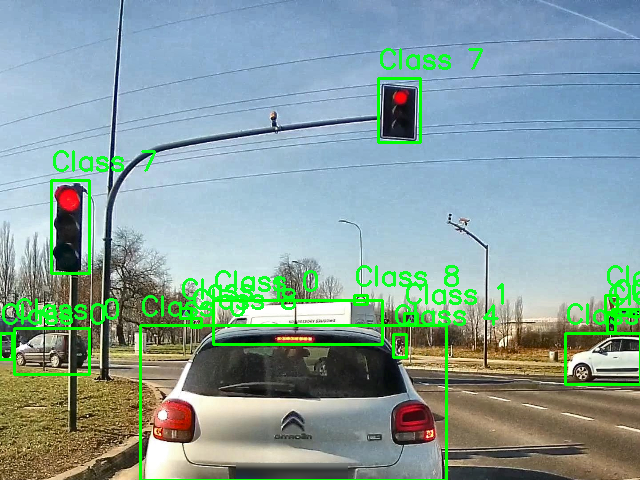

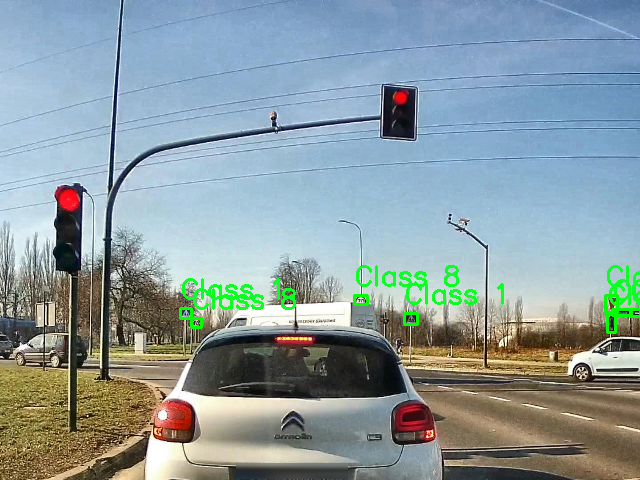

In [11]:
i = np.random.randint(484)
visualize_boxes(i)
visualize_sign_boxes(i)

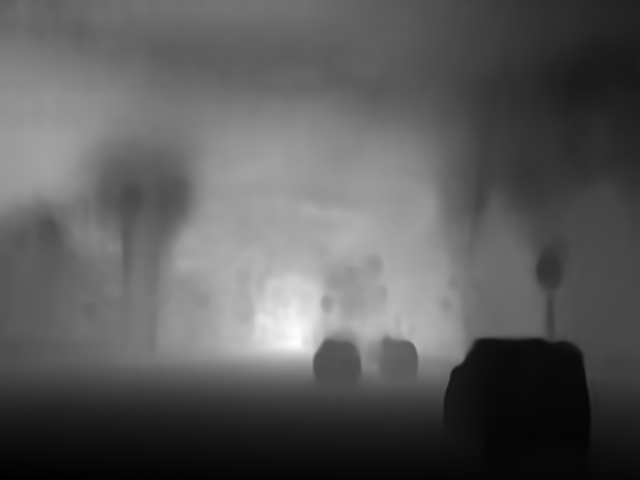

In [12]:
pil_train_images = [Image.fromarray(image) for image in train_images]
predictions = pipe(pil_train_images[0])
predictions["depth"]

In [13]:
def visualize_pred_crop(i, j):
  box=sign_boxes[i][j]
  return Image.fromarray(np.array(pipe(Image.fromarray(train_images[i]))["depth"])[box[1]:box[3],box[0]:box[2]])

def visualize_crop(i, j):
  box=sign_boxes[i][j]
  return Image.fromarray(np.array(train_images[i])[box[1]:box[3],box[0]:box[2]])

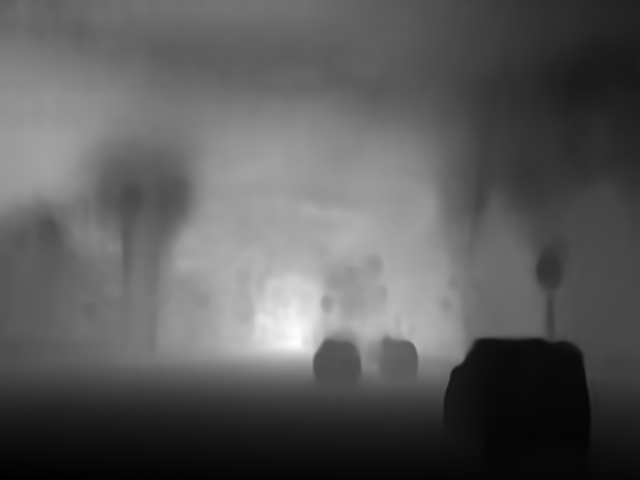

In [14]:
def visualize_pred(i):
  return pipe(Image.fromarray(train_images[i]))["depth"]
visualize_pred(0)

In [15]:
pred_raw = [pipe(image)["predicted_depth"] for image in pil_train_images]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [16]:
def pred_sign_raw(i, j):
  box=sign_boxes[i][j]
  image=pred_raw[i]
  return image[box[1]:box[3],box[0]:box[2]]
def pred_sign_dist(i, j):
  return torch.Tensor.mean(pred_sign_raw(i, j))

In [23]:
sign_distances = []
for i in range(len(sign_boxes)):
  sign_distances.append([])
  for j in range(len(sign_boxes[i])):
    sign_distances[i].append(pred_sign_dist(i,j))

In [22]:
print(sign_distances)

[[tensor(2.7600)], [tensor(2.4001), tensor(3.1283), tensor(4.5689), tensor(4.9405), tensor(5.1390), tensor(5.4391)], [tensor(5.3042)], [tensor(4.9860), tensor(4.0303), tensor(4.9312), tensor(5.0799), tensor(4.7963)], [tensor(6.2998), tensor(5.3058), tensor(3.7656), tensor(5.4065), tensor(6.5396)], [tensor(5.8232)], [tensor(4.1686)], [], [tensor(5.0986), tensor(4.1825), tensor(4.4593)], [tensor(2.7743), tensor(4.7722), tensor(4.9623), tensor(5.7829)], [tensor(5.4463), tensor(4.1496), tensor(4.0480), tensor(4.4736), tensor(3.8958)], [tensor(3.3641)], [tensor(4.1814), tensor(4.5487), tensor(4.1830)], [tensor(1.7022), tensor(2.3745), tensor(3.4549), tensor(3.6019), tensor(3.6596), tensor(1.5620)], [tensor(3.7377), tensor(3.1475), tensor(4.1557), tensor(4.9393)], [tensor(1.8612), tensor(2.3721), tensor(4.4046), tensor(4.0628), tensor(4.2171), tensor(4.7688)], [tensor(2.8545)], [], [tensor(2.6871), tensor(3.3398), tensor(3.4361), tensor(3.3902)], [tensor(6.0615)], [tensor(2.8657), tensor(2.8

In [19]:
def test_dist(i):
  print(sign_distances[i])
  visualize_sign_boxes(i)

[tensor(6.2550)]


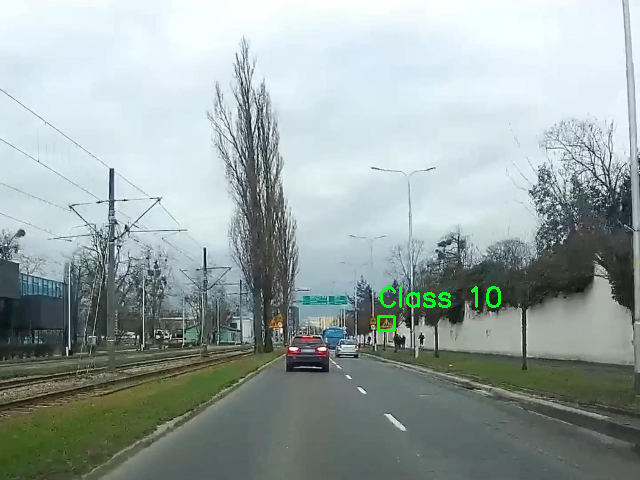

In [25]:
test_dist(np.random.randint(len(sign_boxes)))